# Milestone 3 — Recommendation Evaluation and Model Comparison

### Objective
Evaluate recommendation quality using the metrics required by the project guidance: Precision, Recall, NDCG and Mean Average Precision (MAP). Compare two content-based approaches and a simple popularity baseline.

### Evaluation ground truth and limitation
The dataset's `related_talks` field provides catalogue-level related-talk links. These links are used as offline item-to-item relevance labels. They are **not** individual user ratings or watch-history data, so the scores measure agreement with the dataset's related-talk links, not actual user satisfaction.

## 1. Load dataset and construct relevance labels

In [1]:
from pathlib import Path
import ast, re, string
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from IPython.display import display

DATA_PATH = Path("ted_talks_final_cleaned.csv")
if not DATA_PATH.exists():
    raise FileNotFoundError("Place ted_talks_final_cleaned.csv beside this notebook or update DATA_PATH.")
df = pd.read_csv(DATA_PATH, low_memory=False).drop_duplicates(subset=["talk_id"]).reset_index(drop=True)
df["talk_id"] = pd.to_numeric(df["talk_id"], errors="raise").astype(int)
for col in ["title", "topics", "description", "transcript", "related_talks"]:
    df[col] = df[col].fillna("").astype(str)

talk_id_to_idx = {tid: i for i, tid in enumerate(df["talk_id"])}

def parse_related_ids(value):
    try:
        parsed = ast.literal_eval(value)
        if isinstance(parsed, dict):
            return {int(k) for k in parsed.keys()}
        if isinstance(parsed, (list, tuple, set)):
            return {int(x) for x in parsed}
    except (ValueError, SyntaxError, TypeError):
        return set()
    return set()

relevance = {}
for i, row in df.iterrows():
    related_ids = parse_related_ids(row["related_talks"])
    relevant_idx = {talk_id_to_idx[x] for x in related_ids if x in talk_id_to_idx and talk_id_to_idx[x] != i}
    if relevant_idx:
        relevance[i] = relevant_idx

print("Catalogue size:", len(df))
print("Queries with at least one in-catalogue related talk:", len(relevance))
print("Average relevant candidates per query:", round(np.mean([len(v) for v in relevance.values()]), 2))

/home/oai/.config/matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /tmp/matplotlib-yamyi1ff because there was an issue with the default path (/home/oai/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


Catalogue size: 4005
Queries with at least one in-catalogue related talk: 4004
Average relevant candidates per query: 5.94


## 2. Build comparison recommenders

In [2]:
def normalize_text(text):
    text = str(text).lower()
    text = text.translate(str.maketrans("", "", string.punctuation))
    return re.sub(r"\s+", " ", text).strip()

# Model A: combined content (title, topics, description and transcript).
combined_text = (
    df["title"] + " " + df["title"] + " " +
    df["topics"] + " " + df["topics"] + " " +
    df["description"] + " " + df["transcript"]
).map(normalize_text)

combined_vectorizer = TfidfVectorizer(
    stop_words="english", max_features=50000, min_df=2, max_df=0.95,
    ngram_range=(1, 2), sublinear_tf=True, dtype=np.float32
)
combined_matrix = combined_vectorizer.fit_transform(combined_text)

# Model B: topic-only TF-IDF baseline.
topic_vectorizer = TfidfVectorizer(
    stop_words="english", max_features=10000, min_df=1,
    ngram_range=(1, 2), dtype=np.float32
)
topic_matrix = topic_vectorizer.fit_transform(df["topics"].map(normalize_text))

# Baseline C: rank by global views (not personalized).
views = pd.to_numeric(df.get("views", pd.Series(np.zeros(len(df)))), errors="coerce").fillna(0).to_numpy()
popularity_order = np.argsort(views)[::-1]

print("Combined-content matrix:", combined_matrix.shape)
print("Topic-only matrix:", topic_matrix.shape)
print("Popularity baseline prepared.")

Combined-content matrix: (4005, 50000)
Topic-only matrix: (4005, 10000)
Popularity baseline prepared.


## 3. Define evaluation metrics

In [3]:
K = 5

def precision_at_k(ranked, relevant, k=K):
    return len(set(ranked[:k]) & relevant) / k

def recall_at_k(ranked, relevant, k=K):
    return len(set(ranked[:k]) & relevant) / len(relevant) if relevant else 0.0

def average_precision_at_k(ranked, relevant, k=K):
    if not relevant:
        return 0.0
    hits, score = 0, 0.0
    for rank, item in enumerate(ranked[:k], start=1):
        if item in relevant:
            hits += 1
            score += hits / rank
    return score / min(len(relevant), k)

def ndcg_at_k(ranked, relevant, k=K):
    gains = [1 if item in relevant else 0 for item in ranked[:k]]
    dcg = sum(gain / np.log2(rank + 1) for rank, gain in enumerate(gains, start=1))
    ideal_hits = min(len(relevant), k)
    idcg = sum(1 / np.log2(rank + 1) for rank in range(1, ideal_hits + 1))
    return dcg / idcg if idcg else 0.0

def evaluate_rankings(rankings, relevance_map):
    rows = []
    for query_idx, relevant in relevance_map.items():
        ranked = rankings[query_idx]
        rows.append({
            "Precision@5": precision_at_k(ranked, relevant),
            "Recall@5": recall_at_k(ranked, relevant),
            "MAP@5": average_precision_at_k(ranked, relevant),
            "NDCG@5": ndcg_at_k(ranked, relevant)
        })
    return pd.DataFrame(rows).mean().to_dict()

## 4. Generate rankings and calculate metrics

In [4]:

K = 5
eval_query_indices = sorted(relevance)
if len(eval_query_indices) > 250:
    rng = np.random.default_rng(42)
    eval_query_indices = sorted(rng.choice(eval_query_indices, size=250, replace=False).tolist())

def batch_top_k(matrix, query_indices, k=K):
    # One sparse matrix multiplication, then rank the dense query-by-catalogue score block.
    score_block = (matrix[query_indices] @ matrix.T).toarray()
    score_block[np.arange(len(query_indices)), query_indices] = -1.0
    candidate_idx = np.argpartition(-score_block, kth=k-1, axis=1)[:, :k]
    ranked = []
    for row, candidates in zip(score_block, candidate_idx):
        ranked.append(candidates[np.argsort(-row[candidates], kind="stable")].astype(int).tolist())
    return ranked

combined_ranked_rows = batch_top_k(combined_matrix, eval_query_indices, K)
topic_ranked_rows = batch_top_k(topic_matrix, eval_query_indices, K)
popularity_ranked_rows = []
for q_idx in eval_query_indices:
    popularity_ranked_rows.append([int(x) for x in popularity_order if int(x) != q_idx][:K])

combined_rankings = dict(zip(eval_query_indices, combined_ranked_rows))
topic_rankings = dict(zip(eval_query_indices, topic_ranked_rows))
popularity_rankings = dict(zip(eval_query_indices, popularity_ranked_rows))
eval_relevance = {i: relevance[i] for i in eval_query_indices}

results = {
    "TF-IDF: Title + Topics + Description + Transcript": evaluate_rankings(combined_rankings, eval_relevance),
    "TF-IDF: Topics Only": evaluate_rankings(topic_rankings, eval_relevance),
    "Popularity Baseline: Views": evaluate_rankings(popularity_rankings, eval_relevance)
}
print(f"Evaluation query sample: {len(eval_query_indices)} (random_state=42); candidate catalogue: {len(df)} talks.")
results_df = pd.DataFrame(results).T.reset_index(names="Approach").round(4)
display(results_df)


Evaluation query sample: 250 (random_state=42); candidate catalogue: 4005 talks.


,Approach,Precision@5,Recall@5,MAP@5,NDCG@5
0,TF-IDF: Title + Topics + Description + Transcript,0.3344,0.2825,0.2697,0.3847
1,TF-IDF: Topics Only,0.1384,0.1163,0.0931,0.1568
2,Popularity Baseline: Views,0.0016,0.0013,0.0007,0.0015


## 5. Visualize model comparison

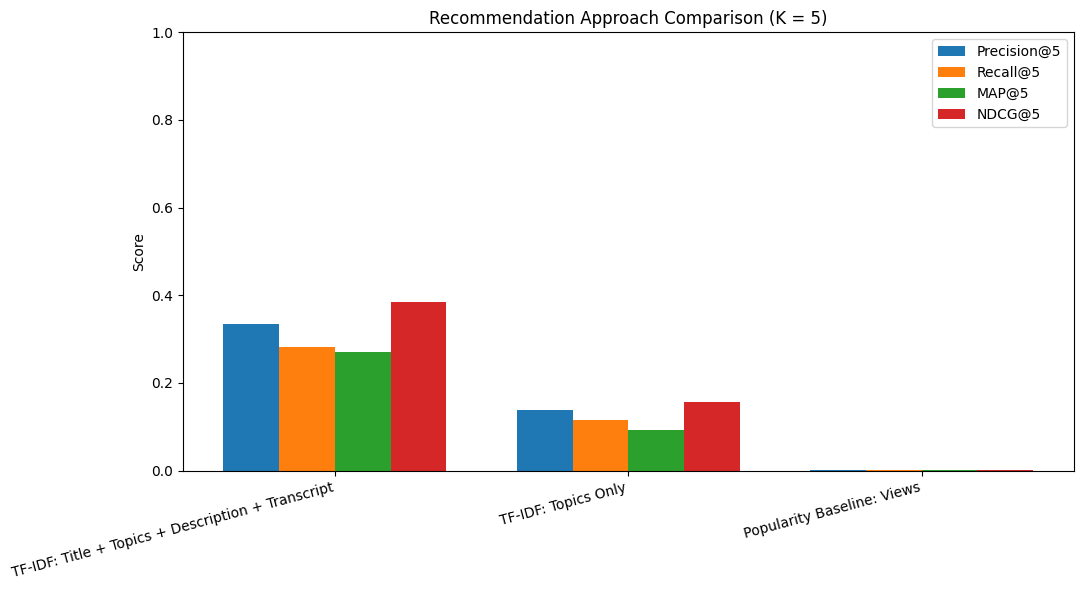

In [5]:
OUTPUT_DIR = Path("outputs_milestone3")
OUTPUT_DIR.mkdir(exist_ok=True)
results_df.to_csv(OUTPUT_DIR / "recommendation_model_comparison.csv", index=False)

metric_cols = ["Precision@5", "Recall@5", "MAP@5", "NDCG@5"]
fig, ax = plt.subplots(figsize=(11, 6))
x = np.arange(len(results_df))
width = 0.19
for j, metric in enumerate(metric_cols):
    ax.bar(x + (j - 1.5) * width, results_df[metric], width, label=metric)
ax.set_xticks(x)
ax.set_xticklabels(results_df["Approach"], rotation=15, ha="right")
ax.set_ylim(0, 1)
ax.set_ylabel("Score")
ax.set_title("Recommendation Approach Comparison (K = 5)")
ax.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "recommendation_metrics_comparison.png", dpi=160)
plt.show()

## 6. Inspect an example recommendation against related-talk links

In [6]:
example_query_idx = next(i for i in eval_query_indices if set(combined_rankings[i]) & relevance[i])
example_query_id = int(df.loc[example_query_idx, "talk_id"])
example_relevant_ids = {int(df.loc[i, "talk_id"]) for i in relevance[example_query_idx]}
example_recs = combined_rankings[example_query_idx]
example_table = df.iloc[example_recs][["talk_id", "title", "speaker_1", "topics"]].copy()
example_table.insert(0, "rank", range(1, len(example_table) + 1))
example_table["in_related_talks_ground_truth"] = example_table["talk_id"].isin(example_relevant_ids)
print("Example query:", df.loc[example_query_idx, "title"], "| talk_id:", example_query_id)
display(example_table)
example_table.to_csv(OUTPUT_DIR / "example_evaluation_recommendations.csv", index=False)

Example query: the gentle genius of bonobos | talk_id: 76


rank,talk_id,title,speaker_1,topics,in_related_talks_ground_truth
1,1102,evolutions gift of play from bonobo apes to humans,isabel behncke,TED Fellows animals culture play science,True
2,1786,the interspecies internet an idea in progress,diana reiss,Internet animals technology,False
3,1931,are we designed to be sexual omnivores,christopher ryan,culture relationships sex,False
4,315,a dig for humanitys origins,louise leakey,Africa ancient world anthropology apes evolution human origins humanity paleontology science,False
5,168,the search for humanitys roots,zeresenay alemseged,Africa anthropology exploration global issues human origins humanity paleontology science,False
